# NYSE、Nasdaq 与 LSE 数据探索

本 Notebook 只读取 `Data/raw/exchanges/NYSE`、`NASDAQ` 和 `LSE` 三个交易所文件夹。它帮助回答：每个文件夹里有什么数据、覆盖哪些股票和日期、竞价成交量是什么分布、缺失值和记录覆盖情况如何。


In [2]:
from __future__ import annotations

import collections
import html
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

PROJECT_NAME = "Eqiuty-Closing-Auction-2026-Yiying"
starts = [Path.cwd().resolve(), (Path.cwd() / PROJECT_NAME).resolve(), (Path.cwd().parent / PROJECT_NAME).resolve()]
candidates = []
for start in starts:
    candidates.extend([start, *start.parents])
PROJECT_ROOT = next(
    (p for p in candidates if (p / "Data" / "raw" / "exchanges").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("找不到项目内的 Data/raw/exchanges 目录。请从项目目录或其子目录打开此 Notebook。")
PARTITION_ROOT = PROJECT_ROOT / "Data" / "raw" / "exchanges"
MARKETS = ("NYSE", "NASDAQ", "LSE")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
print("本 Notebook 的唯一数据根目录： Data/raw/exchanges")


本 Notebook 的唯一数据根目录： Data/raw/exchanges


## 1. 数据类型

- **Bloomberg daily：**每个文件对应一个 ticker，通常每行一个交易日，包含收盘价、日内高低开盘价、全天成交量、成交额、市值，有些文件还带 `CLOSING_AUCTION_VOLUME`。
- **TAQ（仅 NYSE/Nasdaq）：**按交易日保存的股票记录，含不同时间的累计成交量、收盘竞价量、竞价价格和 venue 字段。这里的 `auction_volume` 是美国竞价量候选目标。
- **Checkpoints：**按 ticker-date 保存若干日内时点的累计成交量和相对价格变化。
- **LSE close ticks：**逐笔收盘窗口记录，包含时间、价格、size、condition 和 venue；无成交日可能用 `NO_TRADES` 标记。

以下统计保留缺失值和空文件状态，不把它们转换为零。


In [3]:
def read_csv_or_empty(path, **kwargs):
    try:
        return pd.read_csv(path, low_memory=False, **kwargs)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


def ticker_from_filename(path):
    return path.stem.replace("_", " ")


def as_numeric(frame, column):
    if column not in frame:
        return pd.Series(np.nan, index=frame.index, dtype="float64")
    return pd.to_numeric(frame[column], errors="coerce")


def quantile_summary(values):
    values = np.asarray(values, dtype="float64")
    values = values[np.isfinite(values)]
    if not len(values):
        return {"n": 0, "mean": np.nan, "median": np.nan, "p90": np.nan, "p99": np.nan, "max": np.nan}
    return {"n": len(values), "mean": float(np.mean(values)), "median": float(np.median(values)),
            "p90": float(np.quantile(values, .90)), "p99": float(np.quantile(values, .99)), "max": float(np.max(values))}


# 逐文件读取 market-specific Bloomberg daily，并累计字段缺失、ticker 覆盖和数值分布。
DAILY_FIELDS = ("PX_LAST", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP", "CLOSING_AUCTION_VOLUME")
daily_results = {}
for market in MARKETS:
    folder = PARTITION_ROOT / market / "Bloomberg" / "daily"
    paths = sorted(folder.glob("*.csv"))
    stock_rows, value_arrays, missing_counts, column_file_counts, column_present_rows = [], collections.defaultdict(list), collections.Counter(), collections.Counter(), collections.Counter()
    date_union, schema_counts, empty_files = set(), collections.Counter(), []
    daily_month_parts = []
    total_rows = 0
    for path in paths:
        frame = read_csv_or_empty(path)
        header = tuple(frame.columns)
        schema_counts[header] += 1
        if frame.empty:
            empty_files.append(path.name)
            stock_rows.append({"ticker": ticker_from_filename(path), "rows": 0, "date_count": 0, "first_date": None, "last_date": None})
            continue
        total_rows += len(frame)
        if "date" in frame:
            dates = pd.to_datetime(frame["date"], errors="coerce")
            valid_dates = dates.dropna()
            date_union.update(valid_dates.dt.strftime("%Y-%m-%d").tolist())
        else:
            dates = pd.Series(pd.NaT, index=frame.index)
            valid_dates = dates.dropna()
        stock_rows.append({"ticker": ticker_from_filename(path), "rows": len(frame),
                           "date_count": valid_dates.nunique(),
                           "first_date": valid_dates.min() if len(valid_dates) else None,
                           "last_date": valid_dates.max() if len(valid_dates) else None})
        for field in DAILY_FIELDS:
            if field in frame:
                column_file_counts[field] += 1
                column_present_rows[field] += len(frame)
                values = as_numeric(frame, field)
                missing_counts[field] += int(values.isna().sum())
                if field in {"PX_VOLUME", "TURNOVER", "CUR_MKT_CAP", "CLOSING_AUCTION_VOLUME"}:
                    value_arrays[field].append(values.to_numpy(dtype="float64"))
        if "date" in frame and "CLOSING_AUCTION_VOLUME" in frame:
            label = as_numeric(frame, "CLOSING_AUCTION_VOLUME")
            temp = pd.DataFrame({"date": dates.dt.to_period("M"), "label": label})
            temp = temp.dropna(subset=["date"])
            temp["date"] = temp["date"].astype(str)
            monthly = temp.groupby("date")["label"].agg(rows="size", observed="count", positive=lambda s: int((s > 0).sum()), total="sum").reset_index()
            daily_month_parts.append(monthly)
    combined_values = {field: np.concatenate(parts) if parts else np.array([], dtype="float64")
                       for field, parts in value_arrays.items()}
    daily_results[market] = {
        "folder": folder, "files": len(paths), "rows": total_rows, "dates": sorted(date_union),
        "schemas": schema_counts, "empty_files": empty_files,
        "stocks": pd.DataFrame(stock_rows), "values": combined_values,
        "missing_counts": missing_counts, "column_file_counts": column_file_counts,
        "column_present_rows": column_present_rows,
        "monthly_parts": daily_month_parts,
    }
print("Bloomberg daily 扫描完成；只读取三个分区内的 daily 文件。")


Bloomberg daily 扫描完成；只读取三个分区内的 daily 文件。


## 2. 文件、日期和股票覆盖范围

统计不同交易所覆盖的数据和时间范围，每只股票有多少日记录，以及市场之间的历史范围是否相同。


,市场,Bloomberg daily,ticker 文件数,记录行数,日期数并集,日期范围
0,NYSE,Bloomberg daily,1506,1942145,1478,2021-01-04 至 2026-10-08
1,NASDAQ,Bloomberg daily,3121,3512460,1452,2021-01-04 至 2026-10-08
2,LSE,Bloomberg daily,1062,1825704,1983,2019-01-02 至 2026-10-13


,市场,ticker 文件数,空文件数,每只股票日期数中位数,P10,P90,最少,最多
0,NYSE,1506,0,1448,553,1448,6,1478
1,NASDAQ,3121,4,1448,269,1448,1,1448
2,LSE,1062,10,1966,1063,1966,1,1969


,市场,文件数,Bloomberg daily 实际列名
0,NYSE,31,"date, CUR_MKT_CAP, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER"
1,NYSE,1320,"date, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER, CUR_MKT_CAP, CLOSING_AUCTION_VOLUME"
2,NYSE,78,"date, CUR_MKT_CAP, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER, CLOSING_AUCTION_VOLUME"
3,NYSE,71,"date, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER, CUR_MKT_CAP"
4,NYSE,2,"date, CUR_MKT_CAP, PX_VOLUME, TURNOVER, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, CLOSING_AUCTION_VOLUME"
5,NYSE,3,"date, PX_VOLUME, TURNOVER, CUR_MKT_CAP, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, CLOSING_AUCTION_VOLUME"
6,NYSE,1,"date, PX_VOLUME, TURNOVER, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, CUR_MKT_CAP, CLOSING_AUCTION_VOLUME"
7,NASDAQ,100,"date, CUR_MKT_CAP, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER"
8,NASDAQ,66,"date, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER, CUR_MKT_CAP"
9,NASDAQ,2712,"date, PX_LAST, PX_OPEN, PX_HIGH, PX_LOW, PX_VOLUME, TURNOVER, CUR_MKT_CAP, CLOSING_AUCTION_VOLUME"


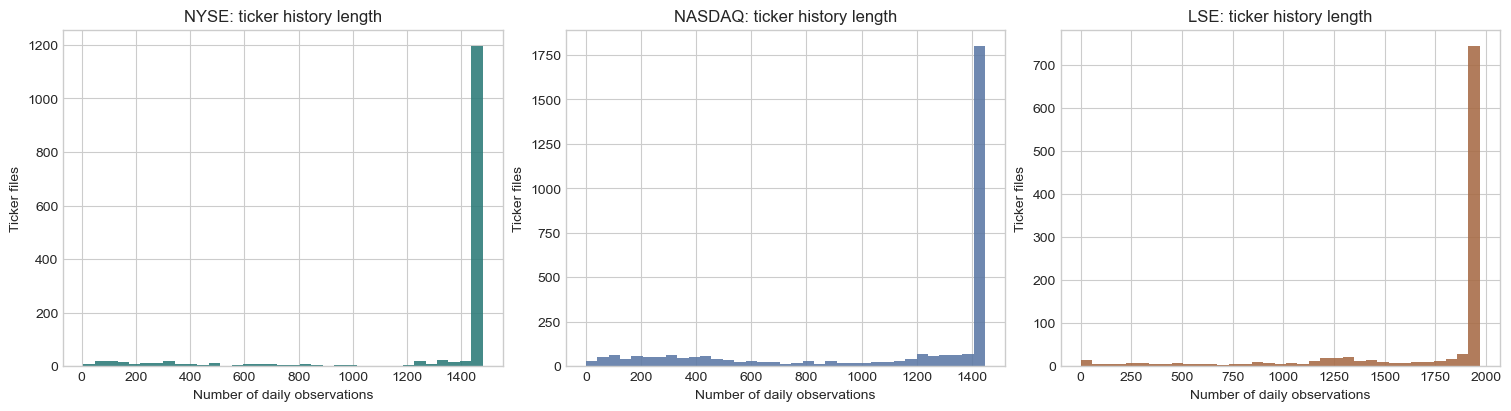

In [4]:
inventory_rows, coverage_rows = [], []
for market, result in daily_results.items():
    nonempty = result["stocks"].query("rows > 0")
    dates = result["dates"]
    inventory_rows.append((market, "Bloomberg daily", result["files"], result["rows"], len(dates),
                           f"{dates[0]} 至 {dates[-1]}" if dates else "无日期"))
    coverage_rows.append((market, result["files"], len(result["empty_files"]),
                          int(nonempty["date_count"].median()) if len(nonempty) else 0,
                          int(nonempty["date_count"].quantile(.10)) if len(nonempty) else 0,
                          int(nonempty["date_count"].quantile(.90)) if len(nonempty) else 0,
                          int(nonempty["date_count"].min()) if len(nonempty) else 0,
                          int(nonempty["date_count"].max()) if len(nonempty) else 0))

show_table = lambda df: display(df.style.format(precision=3).set_table_styles([
    {"selector":"th", "props":[("background-color", "#eef2f5"), ("text-align", "left")]},
    {"selector":"td", "props":[("padding", "5px 8px")]},
]))
show_table(pd.DataFrame(inventory_rows, columns=["市场", "Bloomberg daily", "ticker 文件数", "记录行数", "日期数并集", "日期范围"]))
show_table(pd.DataFrame(coverage_rows, columns=["市场", "ticker 文件数", "空文件数", "每只股票日期数中位数", "P10", "P90", "最少", "最多"]))

schema_rows = []
for market, result in daily_results.items():
    for columns, count in result["schemas"].items():
        schema_rows.append((market, count, ", ".join(columns) if columns else "空文件/无表头"))
show_table(pd.DataFrame(schema_rows, columns=["市场", "文件数", "Bloomberg daily 实际列名"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, market in zip(axes, MARKETS):
    rows = daily_results[market]["stocks"]["date_count"].to_numpy()
    ax.hist(rows, bins=35, color={"NYSE":"#2b7a78", "NASDAQ":"#5b78a5", "LSE":"#a76a45"}[market], alpha=.88)
    ax.set_title(f"{market}: ticker history length")
    ax.set_xlabel("Number of daily observations")
    ax.set_ylabel("Ticker files")
plt.show()


### 字段完整度

这张表说明从Bloomberg获取的数据中，不同字段如何出现在不同文件中，以及存在该列的文件里有多少行是空值。


,市场,字段,含该字段的文件数,总文件数,估算不可用行比例 (%)
0,NYSE,PX_LAST,1506,1506,0.935
1,NYSE,PX_VOLUME,1506,1506,0.704
2,NYSE,TURNOVER,1506,1506,0.704
3,NYSE,CUR_MKT_CAP,1506,1506,0.117
4,NYSE,CLOSING_AUCTION_VOLUME,1404,1506,99.856
5,NASDAQ,PX_LAST,3117,3121,1.842
6,NASDAQ,PX_VOLUME,3117,3121,1.817
7,NASDAQ,TURNOVER,3117,3121,1.817
8,NASDAQ,CUR_MKT_CAP,3116,3121,0.540
9,NASDAQ,CLOSING_AUCTION_VOLUME,2951,3121,99.835


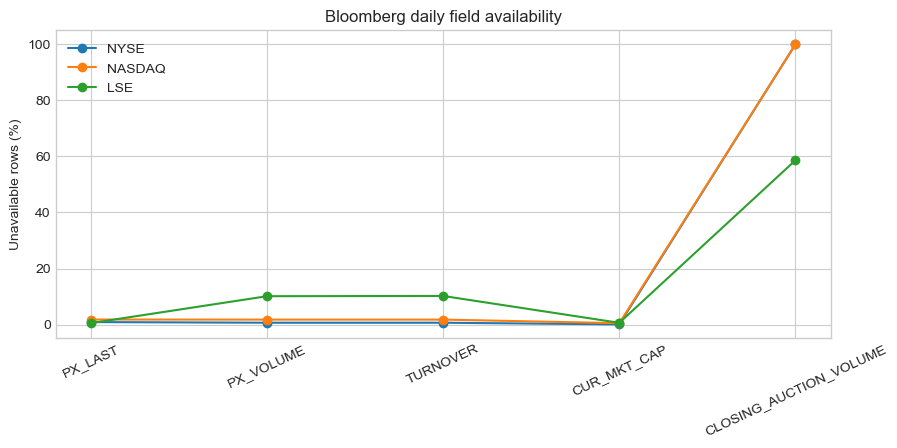

In [5]:
field_rows = []
for market, result in daily_results.items():
    for field in DAILY_FIELDS:
        present_files = result["column_file_counts"][field]
        if present_files == 0:
            missing_pct = np.nan
        else:
            total_rows = result["rows"]
            rows_with_column = result["column_present_rows"][field]
            actual_missing = result["missing_counts"][field]
            available_rows = max(0, rows_with_column - actual_missing)
            # 全部 daily 行作为分母；缺列文件和空值均算不可用。
            missing_pct = 100 * (1 - available_rows / total_rows) if total_rows else np.nan
        field_rows.append((market, field, present_files, result["files"], missing_pct))
field_df = pd.DataFrame(field_rows, columns=["市场", "字段", "含该字段的文件数", "总文件数", "估算不可用行比例 (%)"])
show_table(field_df)

fig, ax = plt.subplots(figsize=(10, 4))
for market in MARKETS:
    sub = field_df[field_df["市场"] == market]
    ax.plot(sub["字段"], sub["估算不可用行比例 (%)"], marker="o", label=market)
ax.set_ylabel("Unavailable rows (%)")
ax.set_title("Bloomberg daily field availability")
ax.tick_params(axis="x", rotation=25)
ax.legend()
plt.show()


## 3. 美国 TAQ 竞价量

TAQ 文件按交易日组织。逐日统计股票记录数、正竞价量、缺失竞价量、不同 dominant venue 以及成交量分布。这里只描述分区本身，不把 `listing_ex` 当作历史挂牌交易所字段。


In [6]:
taq_results = {}
for market in ("NYSE", "NASDAQ"):
    folder = PARTITION_ROOT / market / "WRDS_TAQ" / "days"
    paths = sorted(folder.glob("*.csv.gz"))
    per_day, volume_arrays = [], []
    venue_counts, schema_counts = collections.Counter(), collections.Counter()
    total_rows = positive_rows = missing_rows = zero_rows = negative_rows = 0
    symbol_sets = set()
    duplicate_keys = 0
    ticker_total_dates = collections.Counter()
    ticker_missing_dates = collections.Counter()
    for path in paths:
        frame = read_csv_or_empty(path, compression="gzip")
        schema_counts[tuple(frame.columns)] += 1
        if frame.empty:
            per_day.append({"date": path.name[:8], "rows": 0, "symbols": 0, "positive_labels": 0, "missing_labels": 0, "volume_sum": 0.0, "volume_median": np.nan})
            continue
        total_rows += len(frame)
        values = as_numeric(frame, "auction_volume")
        positive = values[values > 0]
        volume_arrays.append(positive.to_numpy(dtype="float64"))
        positive_rows += int((values > 0).sum())
        missing_rows += int(values.isna().sum())
        zero_rows += int((values == 0).sum())
        negative_rows += int((values < 0).sum())
        if "listing_ex" in frame:
            venue_counts.update(frame["listing_ex"].fillna("(missing)").astype(str).value_counts().to_dict())
        if "sym_root" in frame:
            symbol = frame["sym_root"].fillna("").astype(str)
            if "sym_suffix" in frame:
                symbol = symbol + frame["sym_suffix"].fillna("").astype(str)
            symbol_sets.update(symbol[symbol != ""].unique())
            duplicate_keys += int(frame.duplicated([c for c in ("sym_root", "sym_suffix") if c in frame]).sum())
        # Count unique ticker-date observations, using only dates on which the ticker appears in TAQ.
        if "sym_root" in frame:
            roots = frame["sym_root"].fillna("").astype(str).str.strip()
            suffixes = (frame["sym_suffix"].fillna("").astype(str).str.strip()
                        if "sym_suffix" in frame else pd.Series("", index=frame.index))
            ticker_ids = roots.where(suffixes.eq(""), roots + " (" + suffixes + ")")
            if "date" in frame:
                date_ids = pd.to_datetime(frame["date"], errors="coerce").dt.strftime("%Y-%m-%d")
                date_ids = date_ids.fillna(path.stem[:8])
            else:
                date_ids = pd.Series(path.stem[:8], index=frame.index)
            ticker_day_status = pd.DataFrame({
                "ticker": ticker_ids, "date": date_ids, "target_missing": values.isna()
            })
            ticker_day_status = ticker_day_status[ticker_day_status["ticker"].ne("")]
            # If duplicate rows exist for one ticker-date, count one date; it is missing only if all rows are missing.
            ticker_day_status = ticker_day_status.groupby(
                ["ticker", "date"], as_index=False, sort=False
            )["target_missing"].all()
            ticker_counts = ticker_day_status.groupby("ticker", sort=False).agg(
                total_dates=("date", "size"), missing_dates=("target_missing", "sum")
            )
            ticker_total_dates.update(ticker_counts["total_dates"].astype(int).to_dict())
            ticker_missing_dates.update(ticker_counts["missing_dates"].astype(int).to_dict())

        date_value = pd.to_datetime(frame["date"], errors="coerce").dropna() if "date" in frame else pd.Series(dtype="datetime64[ns]")
        per_day.append({"date": date_value.iloc[0] if len(date_value) else path.name[:8],
                        "rows": len(frame), "symbols": int(frame["sym_root"].nunique()) if "sym_root" in frame else np.nan,
                        "positive_labels": int((values > 0).sum()), "missing_labels": int(values.isna().sum()),
                        "volume_sum": float(values.sum(min_count=1)) if values.notna().any() else np.nan,
                        "volume_median": float(values.median()) if values.notna().any() else np.nan})
    positives = np.concatenate(volume_arrays) if volume_arrays else np.array([], dtype="float64")
    ticker_missingness = pd.DataFrame([
        {"TAQ ticker": ticker,
         "TAQ有数据日期数": int(ticker_total_dates[ticker]),
         "target缺失日期数": int(ticker_missing_dates[ticker])}
        for ticker in ticker_total_dates
    ])
    if len(ticker_missingness):
        ticker_missingness["target缺失率 (%)"] = (
            100 * ticker_missingness["target缺失日期数"] / ticker_missingness["TAQ有数据日期数"]
        )
    taq_results[market] = {"files": len(paths), "rows": total_rows, "positive": positives,
                           "per_day": pd.DataFrame(per_day), "venues": venue_counts,
                           "symbols": len(symbol_sets), "duplicate_keys_per_day": duplicate_keys,
                           "positive_rows": positive_rows, "missing_rows": missing_rows,
                           "zero_rows": zero_rows, "negative_rows": negative_rows, "schemas": schema_counts,
                           "ticker_missingness": ticker_missingness}
print("TAQ 按日扫描完成。")


TAQ 按日扫描完成。


### TAQ target 的逐股票缺失率

每只股票的分母是它在 TAQ 中实际出现的不同日期数，不使用交易所全部日期作分母。同一股票同日若有重复行，先合并为一个股票—日期，只有该日所有行的 `auction_volume` 都缺失或无法转成数值时才计为缺失。零值是观测值，不计为缺失。下表给出各交易所股票缺失率的分位数；全量逐股票明细保存在 `taq_ticker_missingness` 中。


,市场,股票数,P10 缺失率 (%),P25 缺失率 (%),P50 缺失率 (%),P75 缺失率 (%),P90 缺失率 (%),P95 缺失率 (%),P99 缺失率 (%)
0,NYSE,1506,0.000,0.000,0.000,0.166,1.913,18.619,95.138
1,NASDAQ,3119,0.000,0.000,0.000,4.159,27.042,62.473,86.464


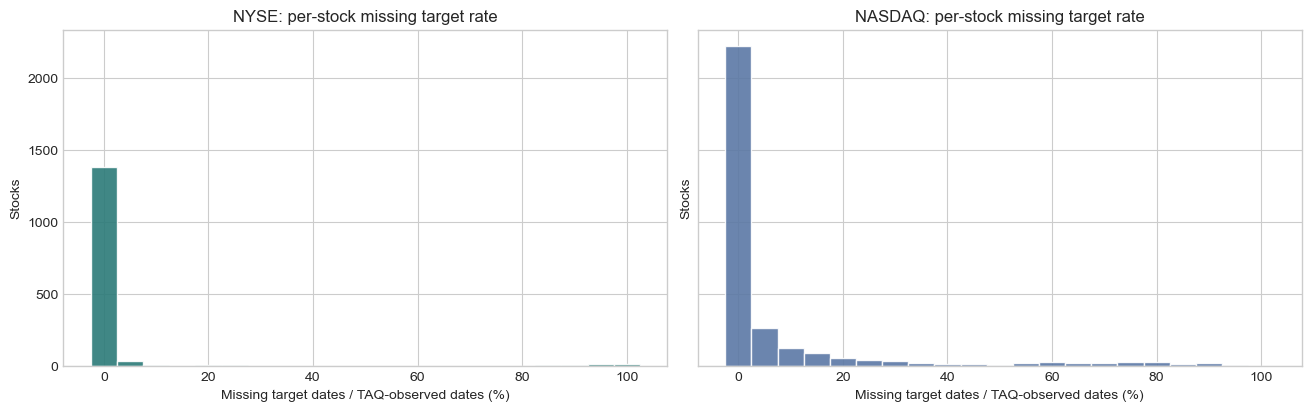

,TAQ ticker,TAQ有数据日期数,target缺失日期数,target缺失率 (%),市场
0,IPHX,10,10,100.000,NASDAQ
1,UCFI,1,1,100.000,NASDAQ
2,SCPQ,151,143,94.702,NASDAQ
3,IDAC,74,70,94.595,NASDAQ
4,FDMM,53,50,94.340,NASDAQ
5,WLCO,49,46,93.878,NASDAQ
6,JONE,31,29,93.548,NASDAQ
7,LTGR,59,55,93.220,NASDAQ
8,CTAA,117,108,92.308,NASDAQ
9,ALOV,127,117,92.126,NASDAQ


In [7]:
taq_ticker_missingness = pd.concat(
    [result["ticker_missingness"].assign(市场=market)
     for market, result in taq_results.items()],
    ignore_index=True,
)

missing_rate_quantiles = (0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)
missing_rate_summary_rows = []
for market, stock_rows in taq_ticker_missingness.groupby("市场", sort=False):
    rates = stock_rows["target缺失率 (%)"]
    row = {"市场": market, "股票数": len(stock_rows)}
    row.update({f"P{int(q * 100)} 缺失率 (%)": rates.quantile(q) for q in missing_rate_quantiles})
    missing_rate_summary_rows.append(row)

missing_rate_summary = pd.DataFrame(missing_rate_summary_rows)
show_table(missing_rate_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, constrained_layout=True)
for ax, market, color in zip(axes, ("NYSE", "NASDAQ"), ("#2b7a78", "#5b78a5")):
    stock_rates = taq_ticker_missingness.loc[
        taq_ticker_missingness["市场"] == market, "target缺失率 (%)"
    ]
    ax.hist(stock_rates, bins=np.arange(-2.5, 102.6, 5), color=color, alpha=.9, edgecolor="white")
    ax.set_title(f"{market}: per-stock missing target rate")
    ax.set_xlabel("Missing target dates / TAQ-observed dates (%)")
    ax.set_ylabel("Stocks")
plt.show()

# 显示缺失率最高的股票作为预览；所有股票的结果都保存在 taq_ticker_missingness。
missing_rate_preview = (
    taq_ticker_missingness.sort_values(
        ["市场", "target缺失率 (%)", "TAQ有数据日期数"],
        ascending=[True, False, False],
    )
    .groupby("市场", sort=False)
    .head(10)
    .reset_index(drop=True)
)
show_table(missing_rate_preview)


### closing auction volume distribution

US目标量使用 TAQ `auction_volume`，LSE 目标量使用 Bloomberg daily `CLOSING_AUCTION_VOLUME`。下面同时展示正成交量的原始股数分位数与 `log1p` 直方图。


,市场,正目标值数量,均值,中位数,P90,P99,最大值
0,NYSE,1557164,279911.460,99435.000,639383.500,2692089.730,314462281.000
1,NASDAQ,2696131,137030.303,14633.000,261585.000,2034126.600,205378788.000
2,LSE,756125,724198.268,73884.000,1189675.400,11119837.480,335949463.000


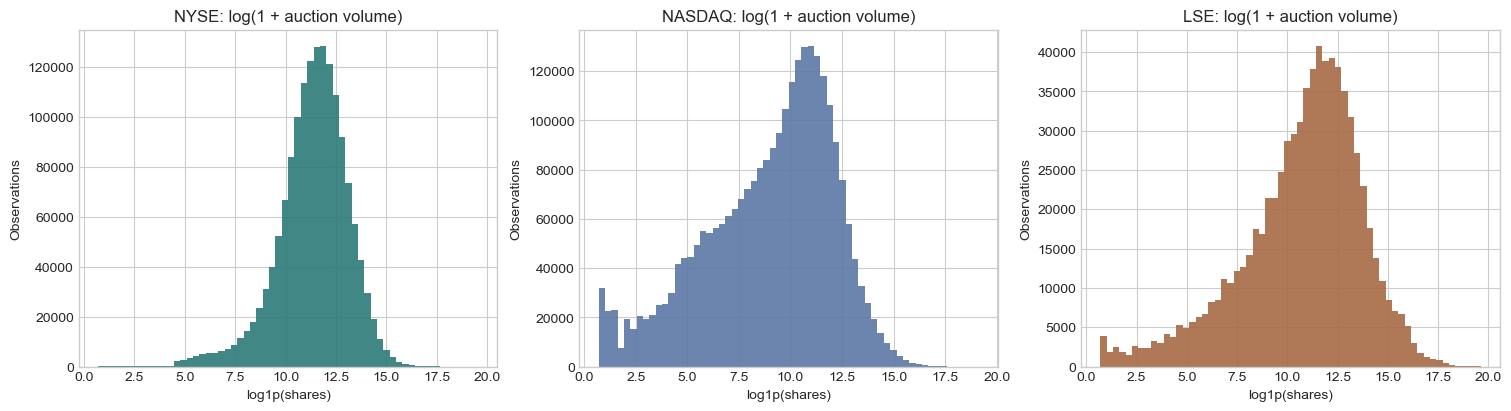

,市场,日期文件数,TAQ 行数,出现过的 ticker 数,正 auction_volume 行,缺失 auction_volume 行,零值行,负值行,同日重复 ticker 键,listing_ex 分布
0,NYSE,1202,1588848,1506,1557164,31684,0,0,0,"{'N': 1532487, 'Q': 21264, '(missing)': 31684, 'A': 3317, 'P': 96}"
1,NASDAQ,1202,2803941,3119,2696131,107810,0,0,0,"{'Q': 2673147, '(missing)': 107810, 'N': 18133, 'A': 4698, 'P': 153}"


,市场,日期文件数,WRDS TAQ 实际列名
0,NYSE,1193,"date, sym_root, sym_suffix, cumvol_10:00, cumvol_12:00, cumvol_14:00, cumvol_15:00, cumvol_15:30, cumvol_15:50, continuous_volume, auction_volume_all, xvol_n, xvol_q, xvol_p, xvol_a, xvol_z, auction_price, n_prints, listing_ex, trf_close_volume, auction_volume"
1,NYSE,9,"date, sym_root, sym_suffix, cumvol_10:00, cumvol_12:00, continuous_volume, auction_volume_all, xvol_n, xvol_q, xvol_p, xvol_a, xvol_z, auction_price, n_prints, listing_ex, trf_close_volume, auction_volume"
2,NASDAQ,1193,"date, sym_root, sym_suffix, cumvol_10:00, cumvol_12:00, cumvol_14:00, cumvol_15:00, cumvol_15:30, cumvol_15:50, continuous_volume, auction_volume_all, xvol_n, xvol_q, xvol_p, xvol_a, xvol_z, auction_price, n_prints, listing_ex, trf_close_volume, auction_volume"
3,NASDAQ,9,"date, sym_root, sym_suffix, cumvol_10:00, cumvol_12:00, continuous_volume, auction_volume_all, xvol_n, xvol_q, xvol_p, xvol_a, xvol_z, auction_price, n_prints, listing_ex, trf_close_volume, auction_volume"


In [8]:
target_arrays = {"NYSE": taq_results["NYSE"]["positive"],
                 "NASDAQ": taq_results["NASDAQ"]["positive"],
                 "LSE": daily_results["LSE"]["values"].get("CLOSING_AUCTION_VOLUME", np.array([]))}
target_arrays["LSE"] = target_arrays["LSE"][np.isfinite(target_arrays["LSE"]) & (target_arrays["LSE"] > 0)]
quant_rows = []
for market, values in target_arrays.items():
    summary = quantile_summary(values)
    quant_rows.append((market, summary["n"], summary["mean"], summary["median"], summary["p90"], summary["p99"], summary["max"]))
show_table(pd.DataFrame(quant_rows, columns=["市场", "正目标值数量", "均值", "中位数", "P90", "P99", "最大值"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, market in zip(axes, MARKETS):
    vals = target_arrays[market]
    if len(vals):
        ax.hist(np.log1p(vals), bins=60, color={"NYSE":"#2b7a78", "NASDAQ":"#5b78a5", "LSE":"#a76a45"}[market], alpha=.9)
    ax.set_title(f"{market}: log(1 + auction volume)")
    ax.set_xlabel("log1p(shares)")
    ax.set_ylabel("Observations")
plt.show()

volume_status = []
for market in ("NYSE", "NASDAQ"):
    r = taq_results[market]
    volume_status.append((market, r["files"], r["rows"], r["symbols"], r["positive_rows"], r["missing_rows"], r["zero_rows"], r["negative_rows"], r["duplicate_keys_per_day"], dict(r["venues"])))
show_table(pd.DataFrame(volume_status, columns=["市场", "日期文件数", "TAQ 行数", "出现过的 ticker 数", "正 auction_volume 行", "缺失 auction_volume 行", "零值行", "负值行", "同日重复 ticker 键", "listing_ex 分布"]))

taq_schema_rows = []
for market, result in taq_results.items():
    for columns, count in result["schemas"].items():
        taq_schema_rows.append((market, count, ", ".join(columns) if columns else "空文件/无表头"))
show_table(pd.DataFrame(taq_schema_rows, columns=["市场", "日期文件数", "WRDS TAQ 实际列名"]))


## 4. 交易量时间变化

美国 TAQ 每个文件对应一个交易日，可以直接看日度竞价总量和有效标签数量。LSE daily 文件按 ticker 分开，先按月汇总标签覆盖与竞价量，再看整体时间变化。


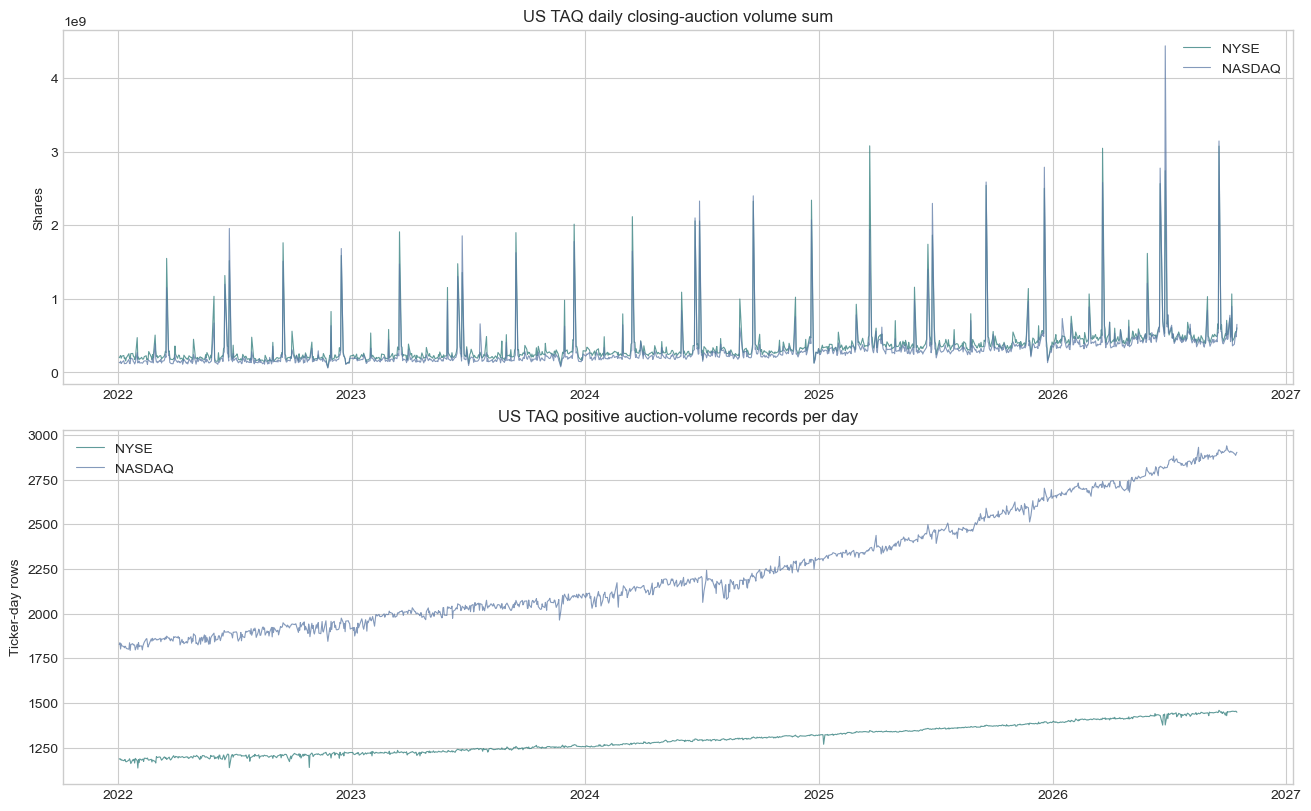

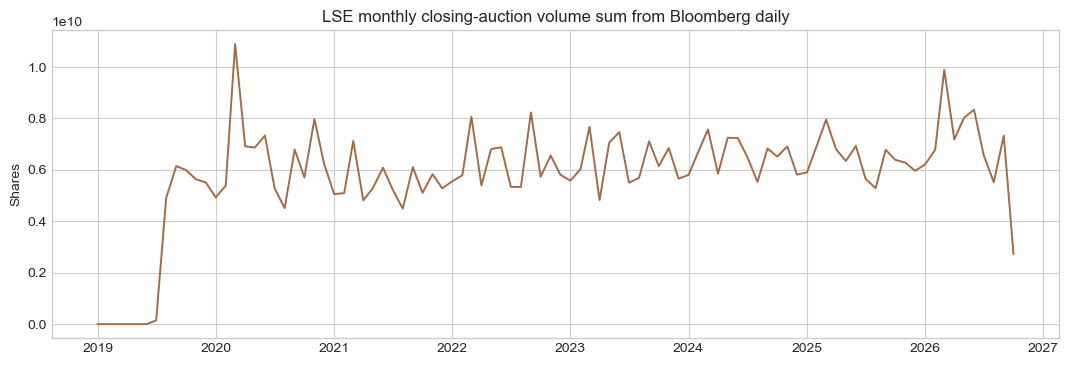

,月份,记录数,非缺失标签数,正标签数,竞价成交量合计
0,2019-01-01 00:00:00,17595,0,0,0.000
1,2019-02-01 00:00:00,16010,0,0,0.000
2,2019-03-01 00:00:00,16847,0,0,0.000
3,2019-04-01 00:00:00,16097,0,0,0.000
4,2019-05-01 00:00:00,16903,0,0,0.000
5,2019-06-01 00:00:00,16125,0,0,0.000
6,2019-07-01 00:00:00,18577,15,15,144074870.000
7,2019-08-01 00:00:00,17008,6584,6580,4902639661.000
8,2019-09-01 00:00:00,16988,6876,6870,6140664026.000
9,2019-10-01 00:00:00,18582,7429,7425,5988962690.000


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
for market, color in (("NYSE", "#2b7a78"), ("NASDAQ", "#5b78a5")):
    frame = taq_results[market]["per_day"].copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame = frame.dropna(subset=["date"]).sort_values("date")
    axes[0].plot(frame["date"], frame["volume_sum"], color=color, alpha=.75, linewidth=.8, label=market)
    axes[1].plot(frame["date"], frame["positive_labels"], color=color, alpha=.75, linewidth=.8, label=market)
axes[0].set_title("US TAQ daily closing-auction volume sum")
axes[0].set_ylabel("Shares")
axes[1].set_title("US TAQ positive auction-volume records per day")
axes[1].set_ylabel("Ticker-day rows")
for ax in axes: ax.legend()
plt.show()

lse_monthly = pd.concat(daily_results["LSE"]["monthly_parts"], ignore_index=True) if daily_results["LSE"]["monthly_parts"] else pd.DataFrame()
if len(lse_monthly):
    lse_monthly = lse_monthly.groupby("date", as_index=False)[["rows", "observed", "positive", "total"]].sum()
    lse_monthly["date"] = pd.to_datetime(lse_monthly["date"])
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(lse_monthly["date"], lse_monthly["total"], color="#a76a45", linewidth=1.4)
    ax.set_title("LSE monthly closing-auction volume sum from Bloomberg daily")
    ax.set_ylabel("Shares")
    plt.show()
    show_table(lse_monthly.head(12).rename(columns={"date":"月份", "rows":"记录数", "observed":"非缺失标签数", "positive":"正标签数", "total":"竞价成交量合计"}))


## 5. LSE close ticks 和日内 checkpoints

close ticks 是逐笔成交/marker 数据。condition 计数可帮助区分 `CA` auction trades、official close/其他 condition 和 `NO_TRADES` 标记。Checkpoint 则描述盘中累计成交量曲线，不是逐笔订单簿。


,LSE close-tick condition,记录数
0,OC,134580
1,CA,65927
2,"AT,AC",64015
3,NO_TRADES,16224


LSE close ticks：280,746 行，1,062 个非空 ticker 文件，142 个日期。
condition 含 CA 的 size 分布： {'n': 65927, 'mean': 681934.9584388793, 'median': 87087.0, 'p90': 1330012.2000000002, 'p99': 9328249.419999978, 'max': 225000000.0}


,市场,checkpoint 文件数,ticker-date 行数,累计成交量时点列
0,NYSE,54,6911,"cumvol_10:00, cumvol_12:00, cumvol_14:00, cumvol_15:00, cumvol_15:30, cumvol_15:50"
1,NASDAQ,30,3840,"cumvol_10:00, cumvol_12:00, cumvol_14:00, cumvol_15:00, cumvol_15:30, cumvol_15:50"
2,LSE,1033,135902,"cumvol_09:00, cumvol_12:00, cumvol_14:00, cumvol_15:30, cumvol_16:00, cumvol_16:25"


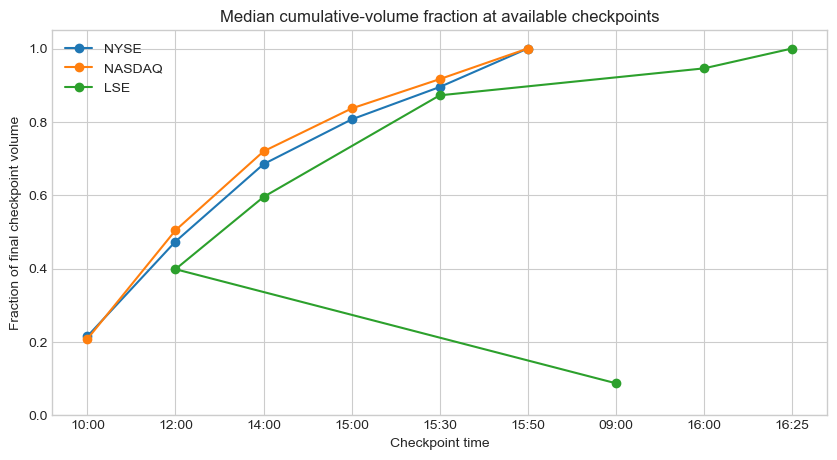

In [10]:
close_folder = PARTITION_ROOT / "LSE" / "Bloomberg" / "close_ticks"
condition_counts, venue_tick_counts = collections.Counter(), collections.Counter()
ca_sizes, close_ticker_rows = [], []
close_dates = set()
close_rows = 0
for path in sorted(close_folder.glob("*.csv")):
    frame = read_csv_or_empty(path)
    if frame.empty:
        continue
    close_rows += len(frame)
    if "cond" in frame:
        condition_counts.update(frame["cond"].fillna("(missing)").astype(str).value_counts().to_dict())
    if "exch" in frame:
        venue_tick_counts.update(frame["exch"].fillna("(missing)").astype(str).value_counts().to_dict())
    if "day" in frame:
        close_dates.update(frame["day"].dropna().astype(str).unique())
    if {"cond", "size"}.issubset(frame.columns):
        size = pd.to_numeric(frame.loc[frame["cond"].astype(str).str.split(",").apply(lambda parts: "CA" in parts), "size"], errors="coerce")
        ca_sizes.append(size.dropna().to_numpy(dtype="float64"))
    close_ticker_rows.append((ticker_from_filename(path), len(frame)))
ca_size_values = np.concatenate(ca_sizes) if ca_sizes else np.array([])
show_table(pd.DataFrame(condition_counts.most_common(15), columns=["LSE close-tick condition", "记录数"]))
print(f"LSE close ticks：{close_rows:,} 行，{len(close_ticker_rows):,} 个非空 ticker 文件，{len(close_dates):,} 个日期。")
if len(ca_size_values):
    print("condition 含 CA 的 size 分布：", quantile_summary(ca_size_values[ca_size_values > 0]))


def load_checkpoints(market):
    folder = PARTITION_ROOT / market / "Bloomberg" / "checkpoints"
    frames = []
    for path in sorted(folder.glob("*.csv")):
        frame = read_csv_or_empty(path)
        if frame.empty:
            continue
        cum_cols = [c for c in frame.columns if c.startswith("cumvol_")]
        if not cum_cols:
            continue
        frames.append(frame[cum_cols].apply(pd.to_numeric, errors="coerce"))
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

checkpoint_data = {market: load_checkpoints(market) for market in MARKETS}
checkpoint_rows = []
for market, frame in checkpoint_data.items():
    checkpoint_rows.append((market, len(list((PARTITION_ROOT / market / "Bloomberg" / "checkpoints").glob("*.csv"))), len(frame),
                            ", ".join(frame.columns) if len(frame.columns) else "无 checkpoint 列"))
show_table(pd.DataFrame(checkpoint_rows, columns=["市场", "checkpoint 文件数", "ticker-date 行数", "累计成交量时点列"]))

fig, ax = plt.subplots(figsize=(10, 5))
for market, frame in checkpoint_data.items():
    if frame.empty: continue
    cum_cols = list(frame.columns)
    final = frame[cum_cols[-1]].replace(0, np.nan)
    fraction = frame[cum_cols].div(final, axis=0)
    profile = fraction.median(axis=0, skipna=True)
    x = [re.search(r"cumvol_(.*)", c).group(1) for c in cum_cols]
    ax.plot(x, profile.to_numpy(), marker="o", label=market)
ax.set_title("Median cumulative-volume fraction at available checkpoints")
ax.set_xlabel("Checkpoint time")
ax.set_ylabel("Fraction of final checkpoint volume")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()


## 6. 价格、全天成交量、成交额和市值的 EDA

这部分进一步按每个市场检查 Bloomberg daily 的日常行情字段：`PX_OPEN`、`PX_HIGH`、`PX_LOW`、`PX_LAST`、`PX_VOLUME`、`TURNOVER`、`CUR_MKT_CAP` 和 `CLOSING_AUCTION_VOLUME`。

对每个字段都会统计全部行的缺失、零值和负值，并记录全量最小值/最大值；分位数和直方图使用固定随机种子、每只股票最多抽 250 条记录，避免大股票压过小股票。另会统计每只股票的字段中位数、OHLC 关系、相邻有效收盘记录的涨跌幅以及日期覆盖。极端变化只作为待核查线索，不自动判定为错误。


In [11]:
DEEP_FIELDS = ("PX_OPEN", "PX_HIGH", "PX_LOW", "PX_LAST", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP", "CLOSING_AUCTION_VOLUME")
DEEP_FIELD_LABELS = {
    "PX_OPEN": "开盘价", "PX_HIGH": "最高价", "PX_LOW": "最低价", "PX_LAST": "收盘价",
    "PX_VOLUME": "全天成交量", "TURNOVER": "全天成交额", "CUR_MKT_CAP": "市值",
    "CLOSING_AUCTION_VOLUME": "收盘竞价量",
}
SAMPLE_PER_TICKER = 250
rng = np.random.default_rng(20261101)
deep_results = {}

for market in MARKETS:
    folder = PARTITION_ROOT / market / "Bloomberg" / "daily"
    paths = sorted(folder.glob("*.csv"))
    field_stats = {field: {"finite": 0, "zero": 0, "negative": 0, "sum": 0.0,
                           "min": np.inf, "max": -np.inf, "files_with_column": 0}
                   for field in DEEP_FIELDS}
    field_samples = collections.defaultdict(list)
    ticker_rows, ticker_field_rows, monthly_parts, return_examples, relationship_rows, top_value_candidates = [], [], [], [], [], []
    zero_volume_checks = {"zero_rows": 0, "with_positive_close": 0, "with_positive_turnover": 0, "with_positive_auction_label": 0}
    dates_union = set()
    total_rows = invalid_dates = duplicate_date_rows = empty_files = 0
    ohlc = {"complete": 0, "high_below_low": 0, "open_outside_range": 0,
            "close_outside_range": 0, "nonpositive_price_values": 0}

    for path in paths:
        frame = read_csv_or_empty(path)
        if frame.empty:
            empty_files += 1
            continue
        n = len(frame)
        total_rows += n
        if "date" in frame:
            dates = pd.to_datetime(frame["date"], errors="coerce")
        else:
            dates = pd.Series(pd.NaT, index=frame.index)
        valid_dates = dates.dropna()
        invalid_dates += int(dates.isna().sum())
        duplicate_date_rows += int(valid_dates.duplicated().sum())
        dates_union.update(valid_dates.dt.normalize().tolist())
        first_date = valid_dates.min() if len(valid_dates) else pd.NaT
        last_date = valid_dates.max() if len(valid_dates) else pd.NaT
        ticker = ticker_from_filename(path)
        numeric = {}

        for field in DEEP_FIELDS:
            if field in frame:
                field_stats[field]["files_with_column"] += 1
                series = pd.to_numeric(frame[field], errors="coerce")
            else:
                series = pd.Series(np.nan, index=frame.index, dtype="float64")
            numeric[field] = series
            arr = series.to_numpy(dtype="float64")
            finite = arr[np.isfinite(arr)]
            stat = field_stats[field]
            stat["finite"] += int(len(finite))
            stat["zero"] += int((finite == 0).sum())
            stat["negative"] += int((finite < 0).sum())
            if len(finite):
                stat["sum"] += float(finite.sum())
                stat["min"] = min(stat["min"], float(finite.min()))
                stat["max"] = max(stat["max"], float(finite.max()))
                sample = rng.choice(finite, size=SAMPLE_PER_TICKER, replace=False) if len(finite) > SAMPLE_PER_TICKER else finite
                field_samples[field].append(sample)
                if field in {"PX_LAST", "PX_HIGH", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP", "CLOSING_AUCTION_VOLUME"}:
                    finite_positions = np.flatnonzero(np.isfinite(arr))
                    top_positions = finite_positions[np.argsort(arr[finite_positions])[-3:]]
                    for pos in top_positions:
                        top_value_candidates.append({"市场": market, "股票": ticker, "字段": DEEP_FIELD_LABELS[field],
                                                     "日期": dates.iloc[int(pos)], "值": float(arr[int(pos)])})
                ticker_field_rows.append({
                    "market": market, "ticker": ticker, "field": field, "rows": n,
                    "finite": len(finite), "missing_pct": 100 * (1 - len(finite) / n),
                    "zero_pct": 100 * float((finite == 0).sum()) / len(finite),
                    "negative_pct": 100 * float((finite < 0).sum()) / len(finite),
                    "ticker_median": float(np.median(finite)), "ticker_max": float(finite.max()),
                    "constant": bool(len(finite) > 1 and np.all(finite == finite[0])),
                })
            else:
                ticker_field_rows.append({
                    "market": market, "ticker": ticker, "field": field, "rows": n,
                    "finite": 0, "missing_pct": 100.0, "zero_pct": np.nan,
                    "negative_pct": np.nan, "ticker_median": np.nan, "ticker_max": np.nan,
                    "constant": False,
                })

        vol = numeric["PX_VOLUME"].to_numpy(dtype="float64")
        turn = numeric["TURNOVER"].to_numpy(dtype="float64")
        close_for_ratio = numeric["PX_LAST"].to_numpy(dtype="float64")
        relation_valid = np.isfinite(vol) & np.isfinite(turn) & np.isfinite(close_for_ratio) & (vol > 0) & (turn > 0) & (close_for_ratio > 0)
        if int(relation_valid.sum()) >= 30:
            log_vol, log_turn = np.log1p(vol[relation_valid]), np.log1p(turn[relation_valid])
            relation_corr = float(np.corrcoef(log_vol, log_turn)[0, 1]) if np.std(log_vol) and np.std(log_turn) else np.nan
            relation_ratio = turn[relation_valid] / (vol[relation_valid] * close_for_ratio[relation_valid])
            relation_ratio = relation_ratio[np.isfinite(relation_ratio) & (relation_ratio > 0)]
            relationship_rows.append({"市场": market, "ticker": ticker, "记录数": int(relation_valid.sum()),
                                      "log成交量与log成交额相关": relation_corr,
                                      "成交额/(成交量×收盘价)中位数": float(np.median(relation_ratio)) if len(relation_ratio) else np.nan})

        zero_volume = np.isfinite(vol) & (vol == 0)
        zero_volume_checks["zero_rows"] += int(zero_volume.sum())
        zero_volume_checks["with_positive_close"] += int((zero_volume & np.isfinite(close_for_ratio) & (close_for_ratio > 0)).sum())
        zero_volume_checks["with_positive_turnover"] += int((zero_volume & np.isfinite(turn) & (turn > 0)).sum())
        auction_values = numeric["CLOSING_AUCTION_VOLUME"].to_numpy(dtype="float64")
        zero_volume_checks["with_positive_auction_label"] += int((zero_volume & np.isfinite(auction_values) & (auction_values > 0)).sum())

        opn = numeric["PX_OPEN"].to_numpy(dtype="float64")
        high = numeric["PX_HIGH"].to_numpy(dtype="float64")
        low = numeric["PX_LOW"].to_numpy(dtype="float64")
        close = numeric["PX_LAST"].to_numpy(dtype="float64")
        complete = np.isfinite(opn) & np.isfinite(high) & np.isfinite(low) & np.isfinite(close)
        ohlc["complete"] += int(complete.sum())
        ohlc["high_below_low"] += int((np.isfinite(high) & np.isfinite(low) & (high < low)).sum())
        range_ok = np.isfinite(high) & np.isfinite(low) & (high >= low)
        ohlc["open_outside_range"] += int((range_ok & np.isfinite(opn) & ((opn < low) | (opn > high))).sum())
        ohlc["close_outside_range"] += int((range_ok & np.isfinite(close) & ((close < low) | (close > high))).sum())
        ohlc["nonpositive_price_values"] += int(sum((np.isfinite(a) & (a <= 0)).sum() for a in (opn, high, low, close)))

        # Relative changes compare adjacent available positive closes; large moves may reflect splits or data adjustments.
        close_frame = pd.DataFrame({"date": dates, "close": numeric["PX_LAST"]})
        close_frame = close_frame.dropna(subset=["date", "close"]).query("close > 0").sort_values("date")
        close_frame = close_frame.drop_duplicates("date", keep="last")
        returns = close_frame["close"].pct_change(fill_method=None).dropna()
        abs_returns = returns.abs()
        if len(returns):
            ticker_rows.append({
                "market": market, "ticker": ticker, "rows": n,
                "unique_dates": int(valid_dates.nunique()), "duplicate_dates": int(valid_dates.duplicated().sum()),
                "invalid_dates": int(dates.isna().sum()), "first_date": first_date, "last_date": last_date,
                "return_observations": len(returns), "return_gt_20pct": int((abs_returns > .20).sum()),
                "return_gt_50pct": int((abs_returns > .50).sum()), "return_gt_100pct": int((abs_returns > 1.0).sum()),
                "max_abs_return": float(abs_returns.max()), "return_volatility": float(returns.std()),
            })
            flagged = returns[abs_returns > .50].sort_values(key=np.abs, ascending=False).head(5)
            for idx, value in flagged.items():
                return_examples.append({"market": market, "ticker": ticker,
                                        "date": close_frame.loc[idx, "date"], "return": float(value)})
        else:
            ticker_rows.append({
                "market": market, "ticker": ticker, "rows": n,
                "unique_dates": int(valid_dates.nunique()), "duplicate_dates": int(valid_dates.duplicated().sum()),
                "invalid_dates": int(dates.isna().sum()), "first_date": first_date, "last_date": last_date,
                "return_observations": 0, "return_gt_20pct": 0, "return_gt_50pct": 0,
                "return_gt_100pct": 0, "max_abs_return": np.nan, "return_volatility": np.nan,
            })

        month_mask = dates.notna()
        if month_mask.any():
            month_frame = pd.DataFrame({"month": dates.loc[month_mask].dt.to_period("M").astype(str)})
            for field in ("PX_LAST", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP"):
                month_frame[field] = numeric[field].loc[month_mask].to_numpy()
            monthly = month_frame.groupby("month", as_index=False)[["PX_LAST", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP"]].median()
            monthly["market"] = market
            monthly["ticker"] = ticker
            monthly_parts.append(monthly)

    ticker_df = pd.DataFrame(ticker_rows)
    market_dates = np.array(sorted(dates_union), dtype="datetime64[ns]")
    if len(ticker_df) and len(market_dates):
        starts = pd.to_datetime(ticker_df["first_date"]).to_numpy(dtype="datetime64[ns]")
        ends = pd.to_datetime(ticker_df["last_date"]).to_numpy(dtype="datetime64[ns]")
        expected = np.zeros(len(ticker_df), dtype=int)
        valid_span = ~pd.isna(starts) & ~pd.isna(ends)
        expected[valid_span] = np.searchsorted(market_dates, ends[valid_span], side="right") - np.searchsorted(market_dates, starts[valid_span], side="left")
        ticker_df["expected_market_dates_in_span"] = expected
        ticker_df["missing_market_dates_in_span"] = np.maximum(0, expected - ticker_df["unique_dates"].to_numpy())
        ticker_df["coverage_in_span_pct"] = np.where(expected > 0, 100 * ticker_df["unique_dates"] / expected, np.nan)

    deep_results[market] = {
        "files": len(paths), "empty_files": empty_files, "rows": total_rows,
        "invalid_dates": invalid_dates, "duplicate_date_rows": duplicate_date_rows,
        "field_stats": field_stats, "field_samples": field_samples,
        "ticker_df": ticker_df, "ticker_field_df": pd.DataFrame(ticker_field_rows),
        "monthly": pd.concat(monthly_parts, ignore_index=True) if monthly_parts else pd.DataFrame(),
        "return_examples": return_examples, "relationships": relationship_rows,
        "top_values": top_value_candidates, "zero_volume_checks": zero_volume_checks,
        "ohlc": ohlc, "market_dates": len(market_dates),
    }
print("日常行情字段 EDA 扫描完成。仅再次读取三个市场的 Bloomberg daily 分区。")

日常行情字段 EDA 扫描完成。仅再次读取三个市场的 Bloomberg daily 分区。


### 数值分布和每只股票的差异

下表覆盖全市场所有有效数值的缺失、零值和负值计数；分位数来自每只股票等量抽样，因此比较的是典型范围，不会让少数超大文件主导图形。全量极值仍按所有记录计算。接着的表格从“每只股票”角度汇总中位数和缺失比例。


,市场,字段,有该列的文件,有效数值行,不可用行比例%,零值行,负值行,样本中位数,样本P90,样本P99,全量最小值,全量最大值
0,NYSE,开盘价,1506,1922315,1.021,0,0,41.520,198.240,670.843,0.212,807000.000
1,NYSE,最高价,1506,1923994,0.935,0,0,42.080,200.770,676.591,0.212,812855.000
2,NYSE,最低价,1506,1923994,0.935,0,0,40.850,196.260,657.590,0.192,804155.000
3,NYSE,收盘价,1506,1923994,0.935,0,0,41.340,198.570,662.791,0.212,809350.000
4,NYSE,全天成交量,1506,1928468,0.704,18,0,208632.000,1278674.600,5324802.200,0.000,340574718.000
5,NYSE,全天成交额,1506,1928469,0.704,0,0,9724179.500,89262319.000,377821782.000,0.240,12476150000.000
6,NYSE,市值,1506,1939868,0.117,0,0,4192.353,43380.923,283077.864,5.013,1205257.105
7,NYSE,收盘竞价量,1404,2804,99.856,0,0,185313.500,1131789.300,5397584.860,2.000,29781269.000
8,NASDAQ,开盘价,3117,3447765,1.842,0,0,15.180,163.800,79800.918,0.069,450888727818.560
9,NASDAQ,最高价,3117,3447766,1.842,0,0,15.560,167.930,81272.500,0.069,496056381391.532


,市场,字段,有有效值的股票数,每股中位数的市场中位数,每股中位数P10,每股中位数P90,每股缺失率中位数%,全程恒定的股票数
0,NYSE,开盘价,1506,38.998,9.595,172.787,0.000,0
1,NYSE,最高价,1506,39.677,9.800,174.107,0.000,0
2,NYSE,最低价,1506,38.450,9.383,171.615,0.000,0
3,NYSE,收盘价,1506,38.983,9.617,173.130,0.000,0
4,NYSE,全天成交量,1506,193726.500,14344.250,1044321.750,0.000,0
5,NYSE,全天成交额,1506,8868283.750,250206.175,73965465.000,0.000,0
6,NYSE,市值,1506,3842.157,377.218,41940.083,0.000,0
7,NYSE,收盘竞价量,1404,194927.000,23816.700,1152680.400,99.862,1
8,NASDAQ,开盘价,3117,14.295,2.950,131.836,0.000,0
9,NASDAQ,最高价,3117,14.605,3.066,134.432,0.000,0


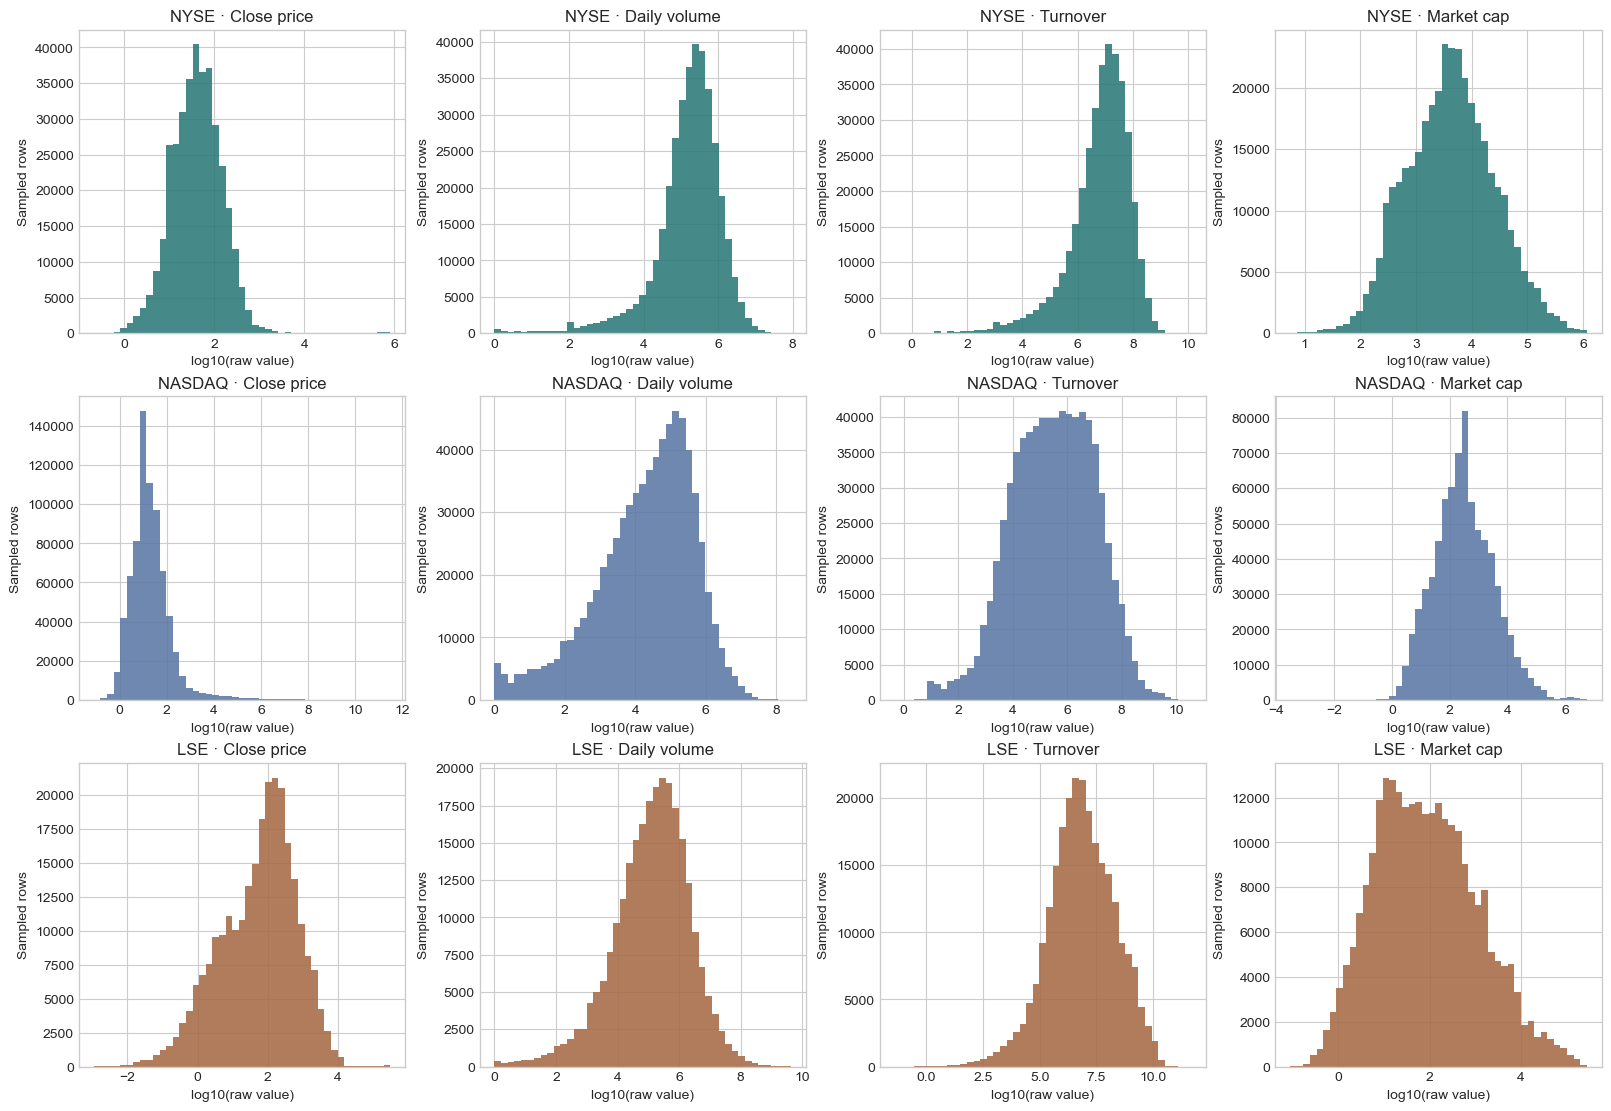

,市场,股票文件数,非空股票文件数,空文件数,市场日期数,重复股票—日期行,日期无法解析行,区间内日期覆盖率中位数%,区间内覆盖率低于95%的股票数
0,NYSE,1506,1506,0,1478,0,0,97.970,1
1,NASDAQ,3121,3117,4,1452,0,0,99.725,34
2,LSE,1062,1052,10,1983,0,0,99.143,88


,市场,PX_VOLUME为零,同时有正收盘价,同时有正成交额,同时有正竞价量
0,NYSE,18,17,18,0
1,NASDAQ,48476,48336,48476,0
2,LSE,287,287,287,0


,市场,股票,字段,日期,值
65,LSE,ENET LN Equity,全天成交量,2026-02-26 00:00:00,4294967295.000
66,LSE,SYME LN Equity,全天成交量,2025-10-23 00:00:00,4294967295.000
67,LSE,FORG LN Equity,全天成交量,2026-09-25 00:00:00,4294967295.000
68,LSE,FORG LN Equity,全天成交量,2026-06-03 00:00:00,4294967295.000
69,LSE,PREM LN Equity,全天成交量,2026-04-13 00:00:00,4294967295.000
60,LSE,ULVR LN Equity,全天成交额,2020-11-27 00:00:00,462735500000.000
61,LSE,AZN LN Equity,全天成交额,2021-07-20 00:00:00,250946000000.000
62,LSE,BATS LN Equity,全天成交额,2025-01-14 00:00:00,137156400000.000
63,LSE,DCC LN Equity,全天成交额,2025-12-19 00:00:00,125182100000.000
64,LSE,SHEL LN Equity,全天成交额,2026-03-20 00:00:00,106418500000.000


In [12]:
deep_field_rows, ticker_field_summary_rows = [], []
for market, result in deep_results.items():
    for field in DEEP_FIELDS:
        stat = result["field_stats"][field]
        total = result["rows"]
        samples = result["field_samples"].get(field, [])
        sample_values = np.concatenate(samples) if samples else np.array([], dtype="float64")
        q = quantile_summary(sample_values)
        deep_field_rows.append({
            "市场": market, "字段": DEEP_FIELD_LABELS[field], "有该列的文件": stat["files_with_column"],
            "有效数值行": stat["finite"], "不可用行比例%": 100 * (1 - stat["finite"] / total) if total else np.nan,
            "零值行": stat["zero"], "负值行": stat["negative"], "样本中位数": q["median"],
            "样本P90": q["p90"], "样本P99": q["p99"],
            "全量最小值": stat["min"] if np.isfinite(stat["min"]) else np.nan,
            "全量最大值": stat["max"] if np.isfinite(stat["max"]) else np.nan,
        })
        sub = result["ticker_field_df"].query("field == @field")
        medians = sub["ticker_median"].dropna()
        ticker_field_summary_rows.append({
            "市场": market, "字段": DEEP_FIELD_LABELS[field], "有有效值的股票数": int(medians.size),
            "每股中位数的市场中位数": float(medians.median()) if len(medians) else np.nan,
            "每股中位数P10": float(medians.quantile(.10)) if len(medians) else np.nan,
            "每股中位数P90": float(medians.quantile(.90)) if len(medians) else np.nan,
            "每股缺失率中位数%": float(sub["missing_pct"].median()) if len(sub) else np.nan,
            "全程恒定的股票数": int(sub["constant"].sum()),
        })
deep_field_df = pd.DataFrame(deep_field_rows)
ticker_field_summary_df = pd.DataFrame(ticker_field_summary_rows)
show_table(deep_field_df)
show_table(ticker_field_summary_df)

fig, axes = plt.subplots(len(MARKETS), 4, figsize=(16, 11), constrained_layout=True)
plot_fields = ("PX_LAST", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP")
for row, market in enumerate(MARKETS):
    for col, field in enumerate(plot_fields):
        ax = axes[row, col]
        parts = deep_results[market]["field_samples"].get(field, [])
        values = np.concatenate(parts) if parts else np.array([])
        values = values[np.isfinite(values) & (values > 0)]
        if len(values):
            ax.hist(np.log10(values), bins=45, color={"NYSE":"#2b7a78", "NASDAQ":"#5b78a5", "LSE":"#a76a45"}[market], alpha=.88)
        english_label = {"PX_LAST":"Close price", "PX_VOLUME":"Daily volume", "TURNOVER":"Turnover", "CUR_MKT_CAP":"Market cap"}[field]
        ax.set_title(f"{market} · {english_label}")
        ax.set_xlabel("log10(raw value)")
        ax.set_ylabel("Sampled rows")
plt.show()

coverage_rows = []
for market, result in deep_results.items():
    t = result["ticker_df"]
    coverage_rows.append({
        "市场": market, "股票文件数": result["files"], "非空股票文件数": len(t), "空文件数": result["empty_files"],
        "市场日期数": result["market_dates"],
        "重复股票—日期行": result["duplicate_date_rows"], "日期无法解析行": result["invalid_dates"],
        "区间内日期覆盖率中位数%": float(t["coverage_in_span_pct"].median()) if len(t) else np.nan,
        "区间内覆盖率低于95%的股票数": int((t["coverage_in_span_pct"] < 95).sum()) if len(t) else 0,
    })
show_table(pd.DataFrame(coverage_rows))

zero_volume_rows = []
for market, result in deep_results.items():
    z = result["zero_volume_checks"]
    zero_volume_rows.append({"市场": market, "PX_VOLUME为零": z["zero_rows"],
                             "同时有正收盘价": z["with_positive_close"],
                             "同时有正成交额": z["with_positive_turnover"],
                             "同时有正竞价量": z["with_positive_auction_label"]})
show_table(pd.DataFrame(zero_volume_rows))

extreme_rows = []
for market, result in deep_results.items():
    cand = pd.DataFrame(result["top_values"])
    if len(cand):
        extreme_rows.append(cand.sort_values("值", ascending=False).groupby("字段", group_keys=False).head(5))
if extreme_rows:
    extreme_df = pd.concat(extreme_rows, ignore_index=True).sort_values(["市场", "字段", "值"], ascending=[True, True, False])
    show_table(extreme_df)

### OHLC 检查、日期断档和大幅价格变化

OHLC 指开盘价、最高价、最低价和收盘价。正常记录通常应满足最高价不低于最低价，开盘价和收盘价落在当天高低价范围内。违反这些关系的记录会被列出来供检查。

日期覆盖率按每只股票自己的首末日期计算：分母是该市场其他股票至少出现过一次的交易日。超过 50% 的相邻有效收盘价变化也只标记为“跳变候选”；拆股、合并、代码变化或价格调整都可能造成这种变化。


,市场,OHLC四价都有的行,最高价低于最低价,开盘价超出高低区间,收盘价超出高低区间,非正价格字段值
0,NYSE,1922315,0,0,0,0
1,NASDAQ,3447763,0,0,0,0
2,LSE,1815010,0,0,0,0


,市场,有收盘价变化记录的股票数,相邻收盘变化绝对值>20%的记录,>50%的记录,>100%的记录,股票最大单次绝对变化中位数%
0,NYSE,1506,2768,155,28,17.645
1,NASDAQ,3116,32546,4310,1044,36.977
2,LSE,1050,9985,1062,226,35.618


,市场,股票,日期,变化%,绝对变化%
3848,LSE,CIZ LN Equity,2021-05-14 00:00:00,40660.870,40660.870
3766,LSE,ASHI LN Equity,2023-06-06 00:00:00,13233.333,13233.333
4056,LSE,GSCU LN Equity,2021-12-20 00:00:00,9000.000,9000.000
4397,LSE,SHR LN Equity,2019-06-24 00:00:00,7919.520,7919.520
3294,NASDAQ,TPST UR Equity,2023-10-11 00:00:00,3970.837,3970.837
1725,NASDAQ,INHD UR Equity,2026-06-08 00:00:00,3660.952,3660.952
1183,NASDAQ,ELPW UR Equity,2026-01-30 00:00:00,3141.107,3141.107
2470,NASDAQ,ORBS UR Equity,2025-09-08 00:00:00,3008.966,3008.966
1108,NASDAQ,DTSS UR Equity,2024-01-23 00:00:00,1541.509,1541.509
3096,NASDAQ,SPRB UR Equity,2025-10-06 00:00:00,1434.118,1434.118


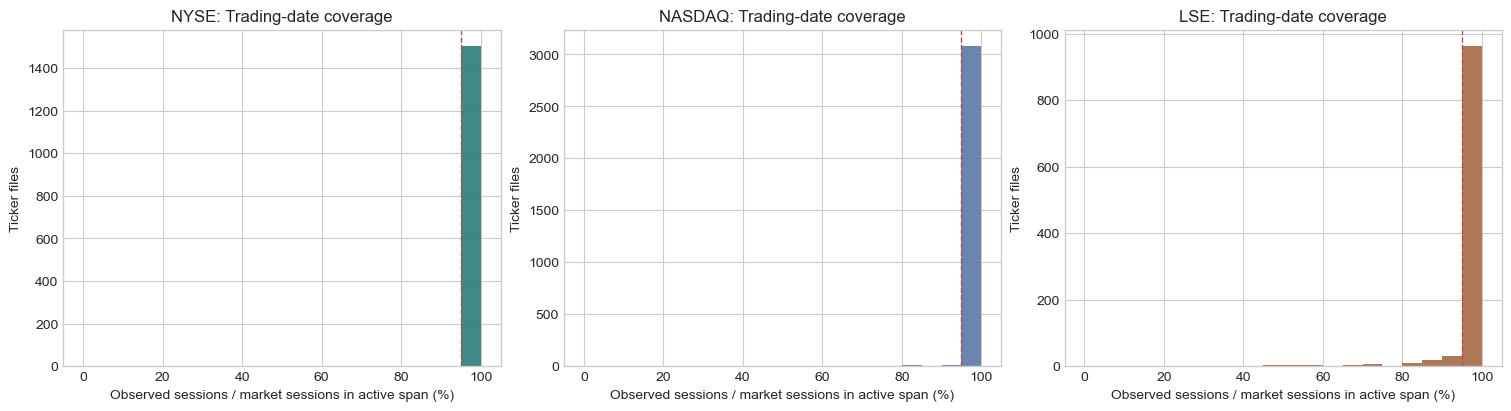

In [13]:
ohlc_rows, jump_summary_rows, jump_examples = [], [], []
for market, result in deep_results.items():
    q = result["ohlc"]
    ohlc_rows.append({"市场": market, "OHLC四价都有的行": q["complete"],
                      "最高价低于最低价": q["high_below_low"], "开盘价超出高低区间": q["open_outside_range"],
                      "收盘价超出高低区间": q["close_outside_range"], "非正价格字段值": q["nonpositive_price_values"]})
    t = result["ticker_df"]
    jump_summary_rows.append({"市场": market, "有收盘价变化记录的股票数": int((t["return_observations"] > 0).sum()),
                              "相邻收盘变化绝对值>20%的记录": int(t["return_gt_20pct"].sum()),
                              ">50%的记录": int(t["return_gt_50pct"].sum()), ">100%的记录": int(t["return_gt_100pct"].sum()),
                              "股票最大单次绝对变化中位数%": float(t["max_abs_return"].median() * 100) if t["max_abs_return"].notna().any() else np.nan})
    jump_examples.extend(result["return_examples"])
show_table(pd.DataFrame(ohlc_rows))
show_table(pd.DataFrame(jump_summary_rows))
jump_df = pd.DataFrame(jump_examples)
if len(jump_df):
    jump_df["绝对变化%"] = jump_df["return"].abs() * 100
    jump_df["变化%"] = jump_df["return"] * 100
    jump_df = jump_df.sort_values("绝对变化%", ascending=False).head(30)
    show_table(jump_df[["market", "ticker", "date", "变化%", "绝对变化%"]].rename(columns={"market":"市场", "ticker":"股票", "date":"日期"}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, market in zip(axes, MARKETS):
    t = deep_results[market]["ticker_df"]["coverage_in_span_pct"].dropna()
    ax.hist(t, bins=np.arange(0, 105, 5), color={"NYSE":"#2b7a78", "NASDAQ":"#5b78a5", "LSE":"#a76a45"}[market], alpha=.9)
    ax.axvline(95, color="#b34d4d", linestyle="--", linewidth=1)
    ax.set_title(f"{market}: Trading-date coverage")
    ax.set_xlabel("Observed sessions / market sessions in active span (%)")
    ax.set_ylabel("Ticker files")
plt.show()

### 行情字段之间的关系和月度变化

这里看两个辅助问题：同一只股票的全天成交量和成交额是否一起变化；成交额与“成交量 × 收盘价”的比值大致落在哪里。这个比值受货币、字段调整方式和成交额定义影响，只用于发现需要查字典或查源数据的市场，不是自动判错标准。

月度曲线先计算每只股票每月的中位数，再取当月股票中位数；它反映分区内股票的典型数值变化，但股票集合会随时间变化，不能当成固定成分指数。


,市场,符合条件的股票数,股票内相关系数中位数,股票内相关系数P10,股票内相关系数P90,比值的股票中位数再取中位数
0,LSE,1034,0.944,0.760,0.991,0.998
1,NASDAQ,3090,0.916,0.531,0.995,1.000
2,NYSE,1498,0.909,0.657,0.989,1.000


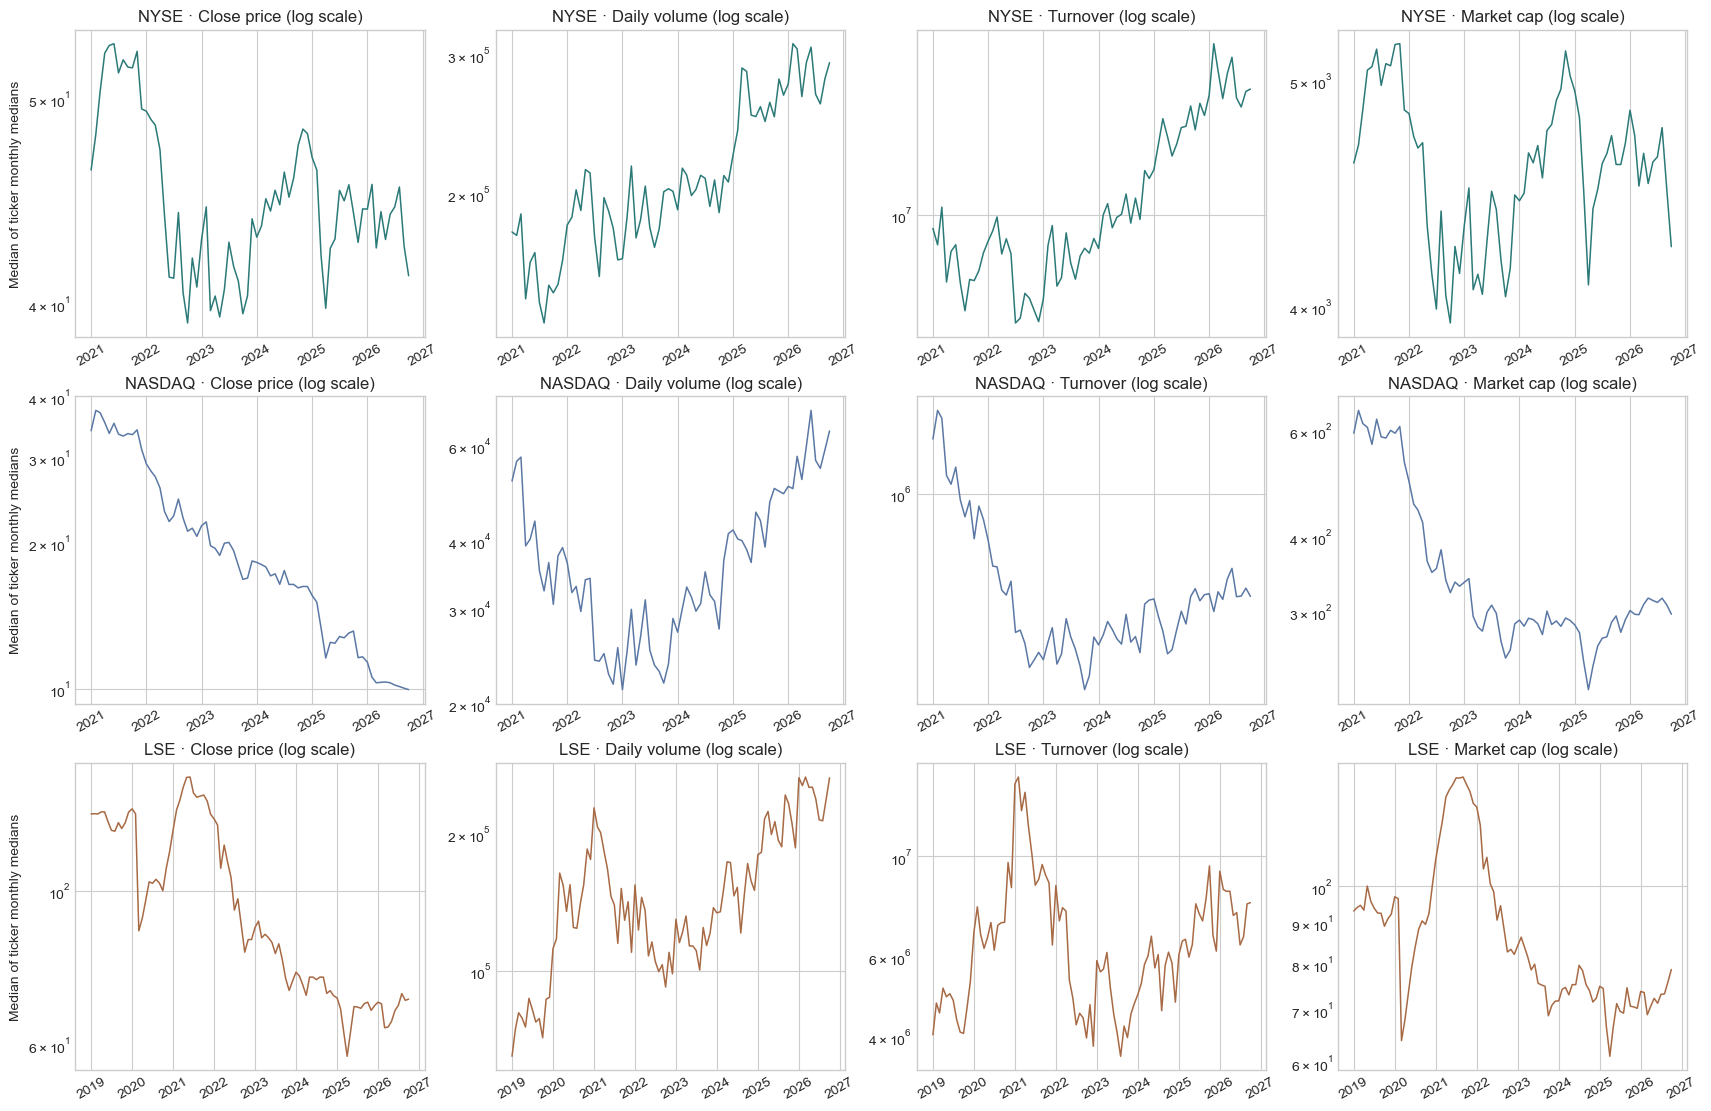

,market,月份数,每月股票数最少,每月股票数最多
0,LSE,94,815,1026
1,NASDAQ,70,1772,3105
2,NYSE,70,1200,1505


In [14]:
relationship_rows = [row for result in deep_results.values() for row in result["relationships"]]
relationship_df = pd.DataFrame(relationship_rows)
relationship_summary = relationship_df.groupby("市场").agg(
    ticker_count=("ticker", "nunique"),
    corr_median=("log成交量与log成交额相关", "median"),
    corr_p10=("log成交量与log成交额相关", lambda s: s.quantile(.10)),
    corr_p90=("log成交量与log成交额相关", lambda s: s.quantile(.90)),
    ratio_median=("成交额/(成交量×收盘价)中位数", "median"),
).reset_index().rename(columns={
    "ticker_count":"符合条件的股票数", "corr_median":"股票内相关系数中位数",
    "corr_p10":"股票内相关系数P10", "corr_p90":"股票内相关系数P90",
    "ratio_median":"比值的股票中位数再取中位数",
}) if len(relationship_df) else pd.DataFrame()
show_table(relationship_summary)

monthly_rows = []
for market, result in deep_results.items():
    if len(result["monthly"]):
        monthly_rows.append(result["monthly"])
monthly_stock_df = pd.concat(monthly_rows, ignore_index=True) if monthly_rows else pd.DataFrame()
monthly_fields = ["PX_LAST", "PX_VOLUME", "TURNOVER", "CUR_MKT_CAP"]
monthly_market_df = monthly_stock_df.groupby(["market", "month"], as_index=False)[monthly_fields].median() if len(monthly_stock_df) else pd.DataFrame()
monthly_counts = monthly_stock_df.groupby(["market", "month"])["ticker"].nunique().rename("股票数").reset_index() if len(monthly_stock_df) else pd.DataFrame()
if len(monthly_market_df):
    monthly_market_df = monthly_market_df.merge(monthly_counts, on=["market", "month"], how="left")
    fig, axes = plt.subplots(3, 4, figsize=(17, 11), constrained_layout=True)
    for row, market in enumerate(MARKETS):
        frame = monthly_market_df[monthly_market_df["market"] == market].copy()
        frame["month"] = pd.to_datetime(frame["month"])
        for col, field in enumerate(monthly_fields):
            ax = axes[row, col]
            valid = frame[field] > 0
            ax.plot(frame.loc[valid, "month"], frame.loc[valid, field], linewidth=1.1,
                    color={"NYSE":"#2b7a78", "NASDAQ":"#5b78a5", "LSE":"#a76a45"}[market])
            ax.set_yscale("log")
            english_label = {"PX_LAST":"Close price", "PX_VOLUME":"Daily volume", "TURNOVER":"Turnover", "CUR_MKT_CAP":"Market cap"}[field]
            ax.set_title(f"{market} · {english_label} (log scale)")
            ax.tick_params(axis="x", rotation=30)
            if col == 0: ax.set_ylabel("Median of ticker monthly medians")
    plt.show()
    show_table(monthly_market_df.groupby("market").agg(月份数=("month", "nunique"),
                 每月股票数最少=("股票数", "min"), 每月股票数最多=("股票数", "max")).reset_index())

## 7. TAQ、close ticks 和 checkpoints 的记录检查

美国 TAQ 除了标签分布，还需要看同一天的股票键是否重复、标签有没有负数，以及不同日期文件的列结构是否一致。LSE 的 close_ticks 会检查价格和数量的无效值；checkpoints 会检查累计成交量是否出现负值或下降。重复的逐笔字段组合只标作“相同记录候选”，不直接删除，因为相同时间和价格可能确实有多笔成交。


In [15]:
taq_quality_rows = []
for market, result in taq_results.items():
    taq_quality_rows.append({
        "市场": market, "日期文件数": result["files"], "TAQ行数": result["rows"],
        "出现过的股票组合数": result["symbols"], "重复股票键行数": result["duplicate_keys_per_day"],
        "auction_volume缺失行": result["missing_rows"], "零值行": result["zero_rows"],
        "负值行": result["negative_rows"], "正值行": result["positive_rows"],
    })
show_table(pd.DataFrame(taq_quality_rows))

checkpoint_quality_rows = []
for market, frame in checkpoint_data.items():
    cols = [c for c in frame.columns if c.startswith("cumvol_")]
    if not len(frame) or not cols:
        checkpoint_quality_rows.append({"市场": market, "行数": len(frame), "时点数值缺失": np.nan,
                                        "含负累计量行": np.nan, "时点间累计量下降行": np.nan, "最后时点为零行": np.nan})
        continue
    values = frame[cols].apply(pd.to_numeric, errors="coerce")
    decreases = values.diff(axis=1) < 0
    checkpoint_quality_rows.append({
        "市场": market, "行数": len(frame), "时点数值缺失": int(values.isna().sum().sum()),
        "含负累计量行": int((values < 0).any(axis=1).sum()),
        "时点间累计量下降行": int(decreases.any(axis=1).sum()),
        "最后时点为零行": int((values.iloc[:, -1] == 0).sum()),
    })
show_table(pd.DataFrame(checkpoint_quality_rows))

close_quality = {"rows": 0, "nonpositive_price": 0, "negative_size": 0, "zero_size": 0,
                 "missing_day": 0, "missing_time": 0, "missing_price": 0, "missing_size": 0,
                 "same_key_candidates": 0}
close_by_condition = collections.defaultdict(lambda: collections.Counter())
close_key_fields = ("day", "time", "price", "size", "cond", "exch")
for path in sorted(close_folder.glob("*.csv")):
    frame = read_csv_or_empty(path)
    if frame.empty: continue
    close_quality["rows"] += len(frame)
    for field in ("day", "time", "price", "size"):
        close_quality["missing_" + field] += int(frame[field].isna().sum()) if field in frame else len(frame)
    if "price" in frame:
        price = pd.to_numeric(frame["price"], errors="coerce")
        close_quality["nonpositive_price"] += int((price <= 0).sum())
    if "size" in frame:
        size = pd.to_numeric(frame["size"], errors="coerce")
        close_quality["negative_size"] += int((size < 0).sum())
        close_quality["zero_size"] += int((size == 0).sum())
    if "cond" in frame:
        cond = frame["cond"].fillna("(missing)").astype(str)
        for label, index in cond.groupby(cond).groups.items():
            rows = frame.loc[index]
            close_by_condition[label]["rows"] += len(rows)
            for field in ("day", "time", "price", "size"):
                close_by_condition[label]["missing_" + field] += int(rows[field].isna().sum()) if field in rows else len(rows)
            if "size" in rows:
                size = pd.to_numeric(rows["size"], errors="coerce")
                close_by_condition[label]["zero_size"] += int((size == 0).sum())
            if "price" in rows:
                price = pd.to_numeric(rows["price"], errors="coerce")
                close_by_condition[label]["nonpositive_price"] += int((price <= 0).sum())
    keys = [field for field in close_key_fields if field in frame]
    if keys:
        close_quality["same_key_candidates"] += int(frame.duplicated(keys).sum())
show_table(pd.DataFrame([{
    "close_ticks总行数": close_quality["rows"], "价格非正行": close_quality["nonpositive_price"],
    "数量负值行": close_quality["negative_size"], "数量为零行": close_quality["zero_size"],
    "缺日期行": close_quality["missing_day"], "缺时间行": close_quality["missing_time"],
    "缺价格行": close_quality["missing_price"], "缺数量行": close_quality["missing_size"],
    "逐笔键完全相同候选行": close_quality["same_key_candidates"],
}]))
condition_quality_rows = []
for label, counts in close_by_condition.items():
    condition_quality_rows.append({"condition": label, "行数": counts["rows"],
                                   "缺日期": counts["missing_day"], "缺时间": counts["missing_time"],
                                   "缺价格": counts["missing_price"], "缺数量": counts["missing_size"],
                                   "零数量": counts["zero_size"], "非正价格": counts["nonpositive_price"]})
show_table(pd.DataFrame(condition_quality_rows).sort_values("行数", ascending=False))

,市场,日期文件数,TAQ行数,出现过的股票组合数,重复股票键行数,auction_volume缺失行,零值行,负值行,正值行
0,NYSE,1202,1588848,1506,0,31684,0,0,1557164
1,NASDAQ,1202,2803941,3119,0,107810,0,0,2696131


,市场,行数,时点数值缺失,含负累计量行,时点间累计量下降行,最后时点为零行
0,NYSE,6911,0,0,0,0
1,NASDAQ,3840,0,0,0,0
2,LSE,135902,0,0,0,63965


,close_ticks总行数,价格非正行,数量负值行,数量为零行,缺日期行,缺时间行,缺价格行,缺数量行,逐笔键完全相同候选行
0,280746,0,0,150804,0,16224,16224,0,0


,condition,行数,缺日期,缺时间,缺价格,缺数量,零数量,非正价格
2,OC,134580,0,0,0,0,134580,0
0,CA,65927,0,0,0,0,0,0
3,"AT,AC",64015,0,0,0,0,0,0
1,NO_TRADES,16224,0,16224,16224,0,16224,0



Next step: 建模前应先确定每个市场的标签定义、股票—日期主键和缺失规则，再按预测时点构造特征。
